# 03 - Unit Reconciliation & Quality Standardization

Fix the `heat-content` unit mismatch (electric power = MMBtu/short ton vs others = Btu/lb) onto one comparable scale.

In [1]:
import sys, os
ROOT = os.getcwd() if os.path.exists(os.path.join(os.getcwd(), "src")) else os.path.dirname(os.getcwd())
sys.path.insert(0, ROOT)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
DATA = os.path.join(ROOT, "data", "eia_coal_consumption_quality_2020_2025.csv")
CHARTS = os.path.join(ROOT, "charts")
os.makedirs(CHARTS, exist_ok=True)
print("ROOT:", ROOT)


ROOT: C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26


In [2]:
def savefig(name):
    p = os.path.join(CHARTS, name)
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print('saved', p)
    plt.show()


In [3]:
from src.data import load_coal_data
from src.clean import clean, ELECTRIC_POWER_SECTORS, NON_ELECTRIC_SECTORS
raw = load_coal_data(DATA)
print('Raw heat-content by sector (two unit scales mixed):')
print(raw.groupby('sector')['heat-content'].agg(['min','median','max']).round(2).to_string())

Raw heat-content by sector (two unit scales mixed):
            min    median       max
sector                             
1           0.0     18.05     26.38
2           0.0     17.19     26.50
3           0.0     15.11     26.36
8        7488.0  11234.00  13999.00
9       13220.0  14431.00  14979.00
10       7208.0  11570.00  14902.00
94          0.0     17.21     26.50
98          0.0     18.17     26.50


In [4]:
df = clean(raw)
print('Reconciled heat_content_btu_lb by sector (single scale):')
print(df.groupby('sector')['heat_content_btu_lb'].agg(['min','median','max']).round(0).to_string())
print('\n2025 flagged as preliminary:', df['is_preliminary'].sum(), 'rows')

Reconciled heat_content_btu_lb by sector (single scale):
            min   median      max
sector                           
1           0.0   9024.0  13189.0
2           0.0   8596.0  13250.0
3           0.0   7557.0  13180.0
8        7488.0  11234.0  13999.0
9       13220.0  14431.0  14979.0
10       7208.0  11570.0  14902.0
94          0.0   8605.0  13250.0
98          0.0   9083.0  13250.0

2025 flagged as preliminary: 285 rows


saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\03_quality_by_sector.png


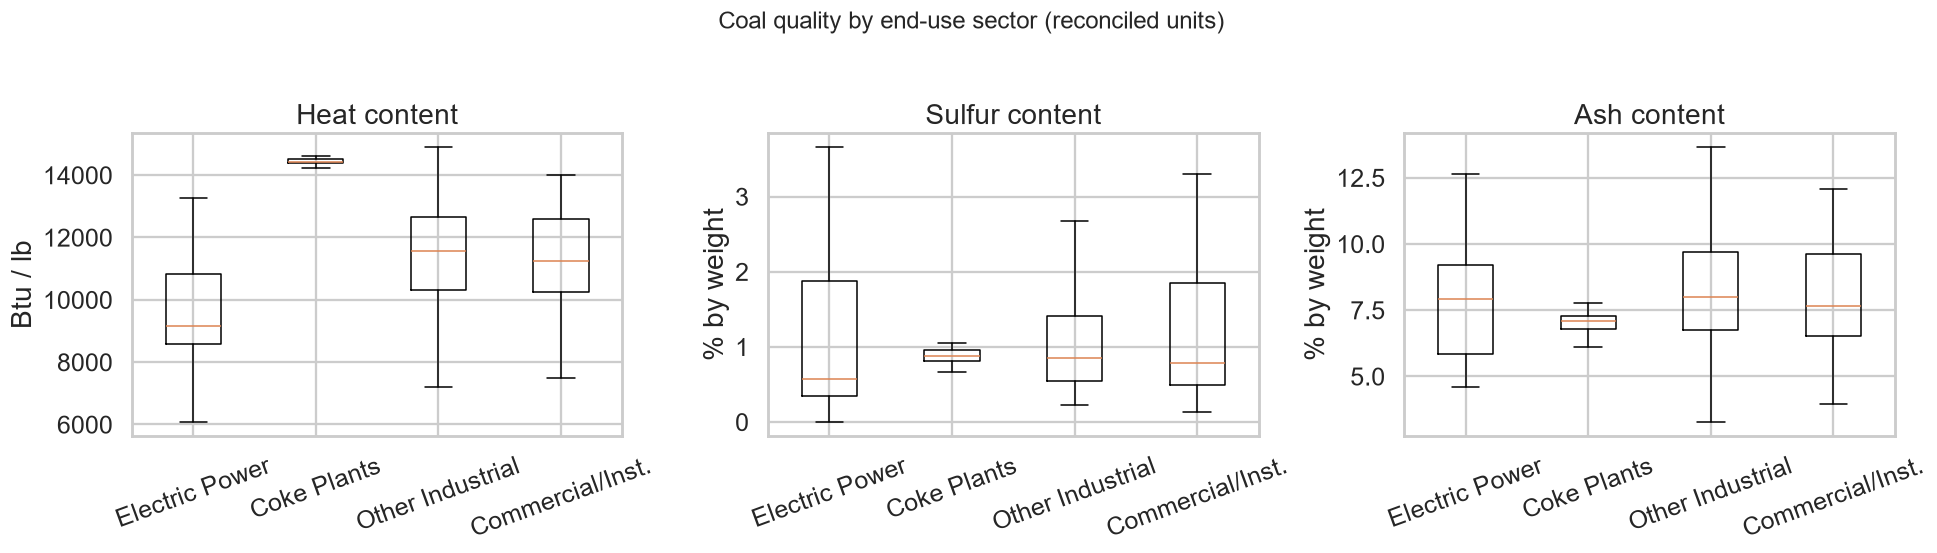

In [5]:
# Chart: average coal quality across sectors on one scale
q = df[df['heat_content_btu_lb'] > 0].copy()
labels = {98:'Electric Power', 9:'Coke Plants', 10:'Other Industrial', 8:'Commercial/Inst.'}
order = [98, 9, 10, 8]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (col, ttl, ylab) in zip(axes, [
    ('heat_content_btu_lb','Heat content','Btu / lb'),
    ('sulfur-content','Sulfur content','% by weight'),
    ('ash-content','Ash content','% by weight')]):
    dat = [q[q['sector']==s][col].dropna() for s in order]
    ax.boxplot(dat, tick_labels=[labels[s] for s in order], showfliers=False)
    ax.set_title(ttl); ax.set_ylabel(ylab); ax.tick_params(axis='x', rotation=20)
plt.suptitle('Coal quality by end-use sector (reconciled units)', y=1.02, fontsize=16)
plt.tight_layout()
savefig('03_quality_by_sector.png')

**Takeaways**
- Electric-power sectors report heat-content in **MMBtu/short ton** (~15-26); non-electric sectors report **Btu/lb** (~7,000-15,000). The `*-units` columns are mislabeled, so units are inferred from magnitude.
- Conversion x500 (1 short ton = 2,000 lb) puts everything on Btu/lb; electric-power coal lands ~8,000-13,000 Btu/lb, metallurgical (coke) coal ~13,000-15,000 Btu/lb.
- Sulfur and ash are consistently `% by weight`. The very high-ash rows (~55%) are PA / Middle-Atlantic IPP CHP plants burning waste coal.